# 03 – Descriptive statistics

Explores the commune dataset before any model: distributions, the main
relationships, differences by commune type, extreme communes and missing data.

- **Input:** `data/processed/communes_2022.csv` (from `code/02_clean_merge.py`)
- **Output:** tables and figures in `Results/descriptive/`

In [1]:
# Packages
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Shared paths, colours and labels live in code/helpers.py
sys.path.append("../code")
import helpers

# The dataset: one row per commune (built by code/02_clean_merge.py)
df = pd.read_csv(helpers.PROCESSED / "communes_2022.csv", encoding="utf-8-sig")

# Folder where this notebook saves its tables and figures
OUT = helpers.results_dir("descriptive")

print(df.shape)

(2115, 51)


## 1. First look
What the table contains, and where values are missing.

In [2]:
#what one commune looks like
df.head()

,code,name,population,foreigners,foreign_share,share_under20,share_65plus,density,canton,major_region,...,tax_per_taxpayer,tax_share_top,share_B,share_C,share_L,share_asylum,share_intl,share_other,filers_per_capita,payers_per_filer
0,1,Aeugst am Albis,1991,294.0,14.8,18.8,20.4,251.7,ZH,Zurich,...,5817.431606,69.507844,4.922150,9.392265,0.000000,0.452034,0.0,0.0,0.603214,0.819317
1,10,Obfelden,5787,1242.0,21.5,23.5,17.5,767.5,ZH,Zurich,...,2499.538288,45.139194,6.912044,14.031450,0.000000,0.518403,0.0,0.0,0.561431,0.785780
2,100,Stadel,2349,317.0,13.5,20.1,17.8,182.2,ZH,Zurich,...,2091.458284,39.128045,5.449127,7.705407,0.170285,0.170285,0.0,0.0,0.618561,0.810048
3,1001,Doppleschwand,806,34.0,4.2,24.3,15.8,116.0,LU,Central CH,...,1051.481143,36.406943,1.116625,3.101737,0.000000,0.000000,0.0,0.0,0.569479,0.762527
4,1002,Entlebuch,3267,231.0,7.1,21.2,19.0,57.4,LU,Central CH,...,1216.051312,36.045062,3.489440,2.969085,0.091827,0.520355,0.0,0.0,0.592287,0.748320


In [3]:
# Is every commune in the table exactly once?
print("Each commune once:", df["code"].is_unique)

# Missing values: only the columns with at least one gap
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False).to_frame("missing_communes")
missing["share_%"] = (100 * missing["missing_communes"] / len(df)).round(1)
missing.to_csv(OUT / "missing_values.csv")
missing

Each commune once: True


,missing_communes,share_%
sa_recipients,490,23.2
sa_rate,490,23.2
jobs_secondary,64,3.0
tax_share_top,48,2.3
jobs_primary,47,2.2
gini_taxable_income,23,1.1
median_taxable_income,23,1.1
jobs_tertiary,11,0.5
foreigners,6,0.3
foreign_share,6,0.3


### What the missing values mean
- **Social assistance (490 communes, 23%)**: hidden by the SFSO in small communes for
  privacy (356 "secret"), 128 blank without explanation, 6 merged communes only partly
  visible. The gaps are concentrated in small communes, so they are **not random**:
  the social assistance models use the 1,625 reported communes, and section 6 compares
  them with the missing ones.
- **Jobs by sector**: small sectors are hidden; total jobs are complete.
- **Share of tax from incomes above CHF 200k (48)**: hidden income classes in small
  communes. Extra outcome only.
- **Median taxable income and income Gini (23)**: communes formed by mergers (medians
  cannot be combined). Used for description only.
- **Foreign share (6), share under 20 (2)**: hidden in tiny communes.
- Population, tax, permits, geography and commune types are complete, so the tax
  models keep almost all communes.

## 2. Summary statistics (Table 1)
Main variables grouped by their role in the analysis.

In [4]:
# Readable names for the table (two tax-split variables are not in helpers yet)
labels = {**helpers.LABELS,
          "filers_per_capita": "Tax filers per resident",
          "payers_per_filer": "Taxpayers per filer"}

# Variables of Table 1, grouped by their role
table1_vars = {
    "Outcomes": ["tax_per_capita", "sa_rate"],
    "Tax split (mechanisms)": ["filers_per_capita", "payers_per_filer",
                               "tax_per_taxpayer", "tax_share_top"],
    "Foreign residents": ["foreign_share", "share_B", "share_C", "share_L",
                          "share_asylum", "share_intl"],
    "Controls": ["population", "share_under20", "share_65plus", "density",
                 "jobs_per_capita", "border_km"],
}

rows = []
for group, columns in table1_vars.items():
    for col in columns:
        values = df[col].dropna()          # each statistic uses the communes where it is known
        rows.append({"Group": group,
                     "Variable": labels[col],
                     "N": len(values),
                     "Mean": values.mean(),
                     "SD": values.std(),
                     "Min": values.min(),
                     "Median": values.median(),
                     "Max": values.max()})

table1 = pd.DataFrame(rows).set_index(["Group", "Variable"]).round(2)
table1.to_csv(OUT / "table1_summary_statistics.csv")
table1

N  \
Group                  Variable                                                 
Outcomes               Federal income tax per resident (CHF)             2115   
                       Social assistance rate (%)                        1625   
Tax split (mechanisms) Tax filers per resident                           2115   
                       Taxpayers per filer                               2115   
                       Federal income tax per taxpayer (CHF)             2115   
                       Share of tax paid by incomes > CHF 200k (%)       2067   
Foreign residents      Foreign residents (% of population)               2109   
                       B permit holders (% of population)                2115   
                       C permit holders (% of population)                2115   
                       L permit holders (% of population)                2115   
                       Asylum-related permits F, N, S (% of population)  2115   
                       International officials (% of population)         2115   
Controls               Population                                        2115   
                       Residents under 20 (%)                            2113   
                       Residents aged 65+ (%)                            2115   
                       Population density (residents per km²)            2115   
                       Jobs per resident                                 2115   
                       Distance to the national border (km)              2115   

                                                                            Mean  \
Group                  Variable                                                    
Outcomes               Federal income tax per resident (CHF)             1176.40   
                       Social assistance rate (%)                           2.04   
Tax split (mechanisms) Tax filers per resident                              0.62   
                       Taxpayers per filer                                  0.75   
                       Federal income tax per taxpayer (CHF)             2529.43   
                       Share of tax paid by incomes > CHF 200k (%)         42.61   
Foreign residents      Foreign residents (% of population)                 17.77   
                       B permit holders (% of population)                   5.89   
                       C permit holders (% of population)                  11.19   
                       L permit holders (% of population)                   0.21   
                       Asylum-related permits F, N, S (% of population)     0.29   
                       International officials (% of population)            0.14   
Controls               Population                                        4168.03   
                       Residents under 20 (%)                              20.35   
                       Residents aged 65+ (%)                              20.28   
                       Population density (residents per km²)             454.78   
                       Jobs per resident                                    0.43   
                       Distance to the national border (km)                21.92   

                                                                               SD  \
Group                  Variable                                                     
Outcomes               Federal income tax per resident (CHF)              1389.02   
                       Social assistance rate (%)                            1.58   
Tax split (mechanisms) Tax filers per resident                               0.08   
                       Taxpayers per filer                                   0.05   
                       Federal income tax per taxpayer (CHF)              2975.97   
                       Share of tax paid by incomes > CHF 200k (%)          18.42   
Foreign residents      Foreign residents (% of population)                   9.78   
         

### Reading Table 1
- Tax per resident is strongly right-skewed (mean 1,176 vs median 781 CHF; max 23,575):
  a few rich communes pull the average up. The models therefore use its **logarithm**.
  Population and density show the same pattern and enter in logs as well.
- Settled foreigners (C permit, 11% on average) outnumber recent ones (B, 6%);
  short-term (L) and asylum-related permits are small on average.
- International officials are zero in the typical commune but reach 24% in a few
  (Geneva area): these tax-exempt residents are checked separately.
- Tax filers per resident exceeds 1 in some communes (more filers than residents),
  probably non-residents taxed there (e.g. holiday homes): checked with the extremes.
- Social assistance is known for 1,625 communes only (see section 1).

## 3. Distributions of the outcomes
Why tax per resident is modelled in logs.

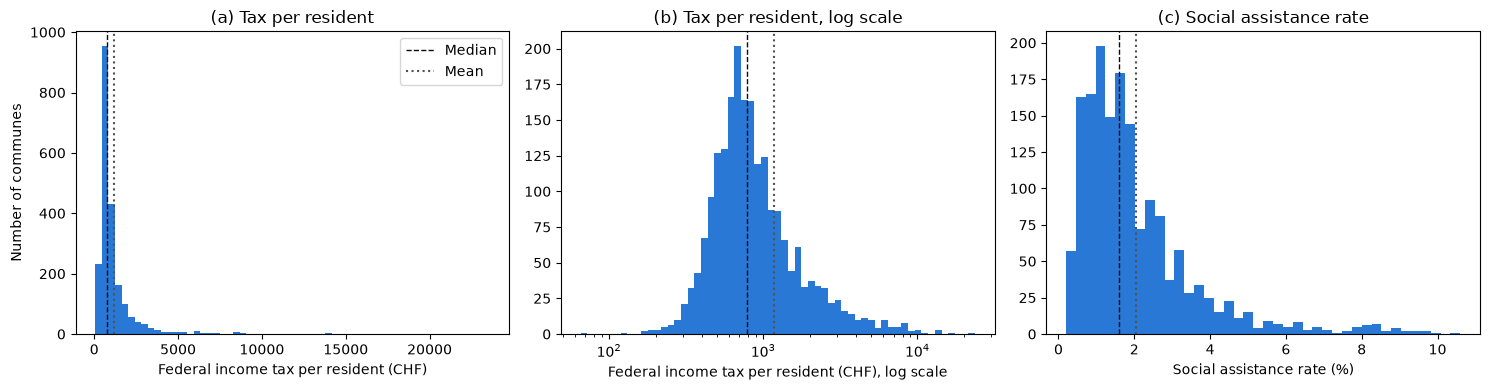

Skewness  tax: 6.03 | log tax: 1.04 | SA rate: 2.09


In [5]:
MAIN = "#2a78d6"                     # main colour of the project (the blue used in helpers)
tax = df["tax_per_capita"]
sa = df["sa_rate"].dropna()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) tax per resident, ordinary scale
axes[0].hist(tax, bins=60, color=MAIN)
axes[0].set(title="(a) Tax per resident", xlabel=labels["tax_per_capita"],
            ylabel="Number of communes")

# (b) same variable on a log scale: bins of equal width in logs
log_bins = np.logspace(np.log10(tax.min()), np.log10(tax.max()), 60)
axes[1].hist(tax, bins=log_bins, color=MAIN)
axes[1].set_xscale("log")
axes[1].set(title="(b) Tax per resident, log scale", xlabel=labels["tax_per_capita"] + ", log scale")

# (c) social assistance rate (reported communes)
axes[2].hist(sa, bins=40, color=MAIN)
axes[2].set(title="(c) Social assistance rate", xlabel=labels["sa_rate"])

# Median (dashed) and mean (dotted) on each panel
for ax, values in zip(axes, [tax, tax, sa]):
    ax.axvline(values.median(), color=helpers.INK["primary"], linestyle="--", linewidth=1, label="Median")
    ax.axvline(values.mean(), color=helpers.INK["secondary"], linestyle=":", linewidth=1.5, label="Mean")
axes[0].legend()

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_outcome_distributions.png")
plt.show()

# Skewness: 0 = symmetric, above 1 = strongly right-skewed
print("Skewness  tax:", round(tax.skew(), 2),
      "| log tax:", round(np.log(tax).skew(), 2),
      "| SA rate:", round(sa.skew(), 2))

### Reading the distributions
- **Tax per resident** is extremely right-skewed (skewness 6.0): most communes are below
  CHF 2,000, but a few rich communes reach 23,575. On a log scale (panel b) the
  distribution is close to symmetric (skewness 1.0). The models therefore use
  **log tax per resident**; coefficients then read as approximate percentage changes.
  The remaining right tail consists of genuinely rich communes and is kept.
- **The social assistance rate** is also right-skewed (skewness 2.1), with most communes
  between 0.5% and 3%. It is kept in percentage points for interpretability; a log
  version is a robustness check. The zigzag pattern comes from rates being reported
  with one decimal.

## 4. The puzzle: how foreign residents, tax and social assistance move together
Spearman (rank) correlations, which are not distorted by skewed variables or outliers.

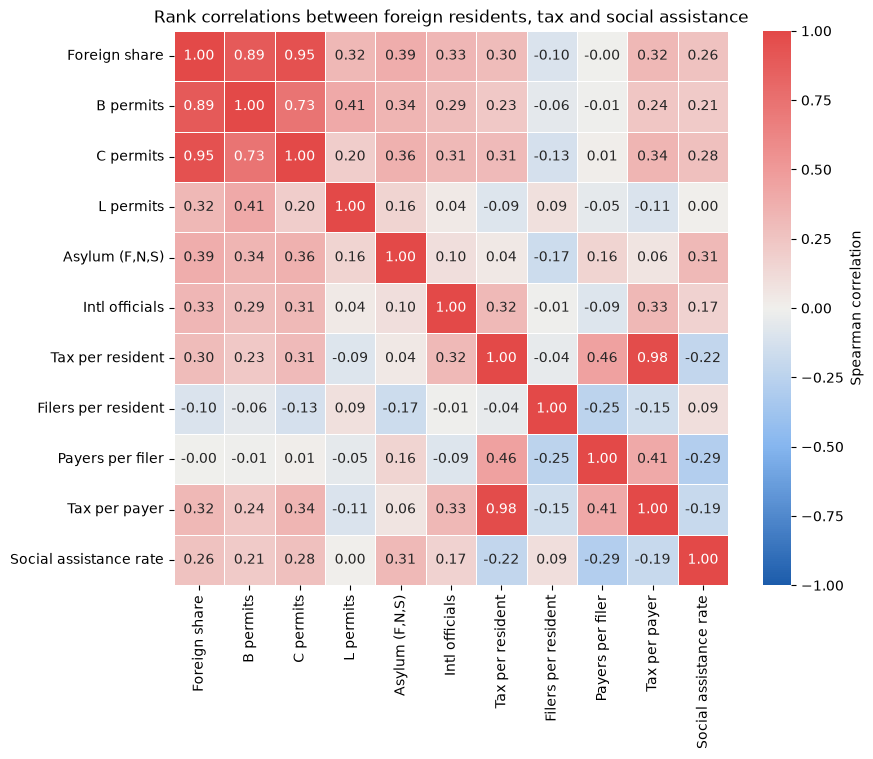

Foreign share - tax per resident: 0.3
Foreign share - social assistance: 0.26
Tax per resident - social assistance: -0.22


In [6]:
# Short names so the heatmap stays readable
short = {"foreign_share": "Foreign share",
         "share_B": "B permits", "share_C": "C permits", "share_L": "L permits",
         "share_asylum": "Asylum (F,N,S)", "share_intl": "Intl officials",
         "tax_per_capita": "Tax per resident",
         "filers_per_capita": "Filers per resident",
         "payers_per_filer": "Payers per filer",
         "tax_per_taxpayer": "Tax per payer",
         "sa_rate": "Social assistance rate"}

corr = df[list(short)].corr(method="spearman").rename(index=short, columns=short)
corr.round(2).to_csv(OUT / "spearman_correlations.csv")

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=helpers.DIVERGING, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Rank correlations between foreign residents, tax and social assistance")
fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_spearman_heatmap.png")
plt.show()

# The three numbers of the puzzle
print("Foreign share - tax per resident:", round(corr.loc["Foreign share", "Tax per resident"], 2))
print("Foreign share - social assistance:", round(corr.loc["Foreign share", "Social assistance rate"], 2))
print("Tax per resident - social assistance:", round(corr.loc["Tax per resident", "Social assistance rate"], 2))

### Reading the correlations
- **The puzzle holds in the final data**: foreign share correlates positively with both
  tax per resident (+0.30) and the social assistance rate (+0.26), although tax and
  social assistance correlate negatively with each other (−0.22).
- B and C permit shares move closely together (0.73): their separate effects will be
  hard to distinguish in a regression (multicollinearity).
- Social assistance goes most with asylum-related permits (+0.31), although recent
  asylum seekers are not counted in the rate: this points to the type of commune they
  live in. Tax goes most with C permits (+0.31) and international officials (+0.32),
  who are tax-exempt themselves but live in rich communes (sorting).
- Tax per resident is almost entirely driven by tax per payer (0.98), and the foreign
  share correlates with tax per payer (+0.32) rather than with filers per resident
  (−0.10): the link with tax runs through richer taxpayers.
- These are raw correlations: part of the pattern may be a city effect, tested next and
  with controls in notebook 04.


## 5. A city effect? Foreign share, tax and social assistance by commune type
If the pattern were only due to cities, it should vanish within each commune type.

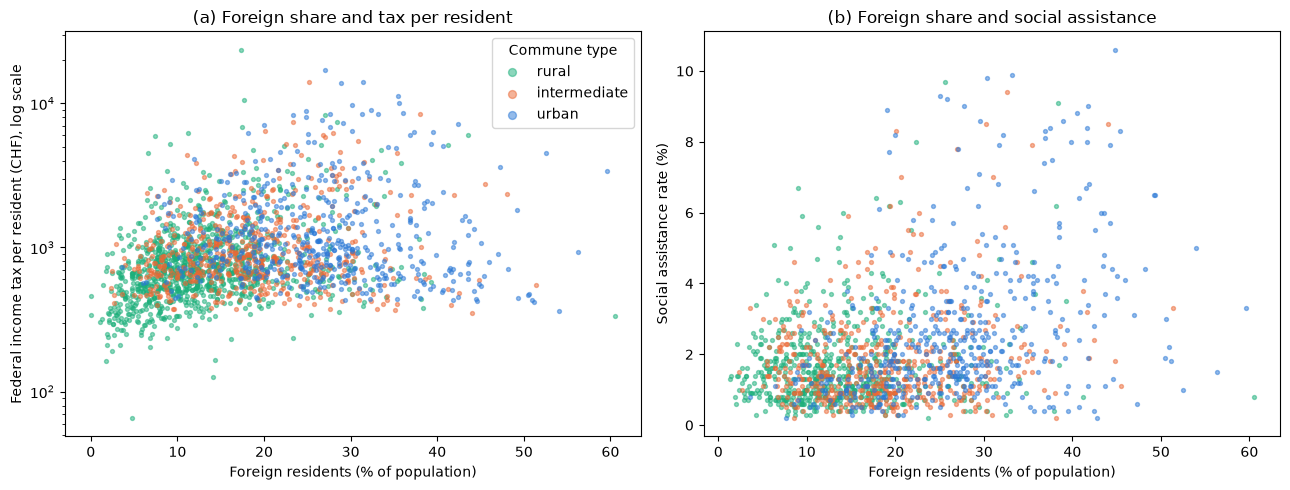

In [7]:
order = helpers.ORDER["urban_rural"]        # urban, intermediate, rural
colors = helpers.COLORS["urban_rural"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for group in reversed(order):               # rural first, so urban points stay visible on top
    d = df[df["urban_rural"] == group]
    axes[0].scatter(d["foreign_share"], d["tax_per_capita"], s=8, alpha=0.5,
                    color=colors[group], label=group)
    axes[1].scatter(d["foreign_share"], d["sa_rate"], s=8, alpha=0.5,
                    color=colors[group], label=group)

axes[0].set_yscale("log")
axes[0].set(title="(a) Foreign share and tax per resident",
            xlabel=labels["foreign_share"], ylabel=labels["tax_per_capita"] + ", log scale")
axes[1].set(title="(b) Foreign share and social assistance",
            xlabel=labels["foreign_share"], ylabel=labels["sa_rate"])
axes[0].legend(title="Commune type", markerscale=2)

fig.tight_layout()
helpers.save_figure(fig, OUT / "fig_scatter_by_commune_type.png")
plt.show()

In [8]:
# The same correlations, computed separately inside each commune type
rows = []
for group in order:
    d = df[df["urban_rural"] == group]
    rows.append({"Commune type": group,
                 "Communes": len(d),
                 "Median foreign share (%)": d["foreign_share"].median(),
                 "Foreign share - tax": d["foreign_share"].corr(d["tax_per_capita"], method="spearman"),
                 "Foreign share - SA": d["foreign_share"].corr(d["sa_rate"], method="spearman")})

within = pd.DataFrame(rows).set_index("Commune type").round(2)
within.to_csv(OUT / "correlations_by_commune_type.csv")
within

,Communes,Median foreign share (%),Foreign share - tax,Foreign share - SA
Commune type,,,,
urban,509,26.1,-0.10,0.38
intermediate,581,17.9,0.10,0.09
rural,1025,11.8,0.31,0.06


### Reading the city-effect check
- Urban communes have far more foreign residents (median 26%) than rural ones (12%).
- The relationships **differ by commune type**: in rural communes, a higher foreign share
  goes with *higher* tax per resident (+0.31) and no more social assistance (+0.06); in
  urban communes, it goes with *more* social assistance (+0.38) and slightly *lower* tax
  (−0.10). Intermediate communes show weak links.
- The pooled pattern (more tax *and* more social assistance) therefore mixes two
  different situations: richer rural communes attracting high earners, and urban
  communes with lower-income foreign residents. This supports the "two kinds of
  foreigners" explanation rather than a pure city effect.
- Consequence for the models: OLS needs an interaction between the foreign share and
  the commune type; flexible models (trees, forests) and clustering can capture this
  heterogeneity directly. Canton fixed effects will test whether it reflects a few regions.

## 6. Extreme communes
Who are the communes at the edges, and are they real or data problems?

In [9]:
# Columns shown for every extreme commune
cols = ["name", "canton", "urban_rural", "population", "foreign_share", "share_intl",
        "tax_per_capita", "filers_per_capita", "sa_rate"]

def extremes(column, n=10, largest=True):
    """The n communes with the highest (or lowest) value of a column."""
    picked = df.nlargest(n, column) if largest else df.nsmallest(n, column)
    return picked[cols].round(2)

tables = {
    "richest (tax per resident)": extremes("tax_per_capita"),
    "poorest (tax per resident)": extremes("tax_per_capita", largest=False),
    "highest social assistance rate": extremes("sa_rate"),
    "most international officials": extremes("share_intl"),
    "more tax filers than residents": df.loc[df["filers_per_capita"] > 1, cols].round(2),
}

for title, table in tables.items():
    print(f"\n=== {title}: {len(table)} communes ===")
    display(table)
    table.to_csv(OUT / f"extremes_{title.split(' (')[0].replace(' ', '_')}.csv", index=False)


=== richest (tax per resident): 10 communes ===


,name,canton,urban_rural,population,foreign_share,share_intl,tax_per_capita,filers_per_capita,sa_rate
1470,Vaux-sur-Morges,VD,rural,185,17.3,0.00,23575.40,0.65,NaN
122,Wollerau,SZ,urban,7495,27.0,0.00,17000.86,0.63,1.4
120,Feusisberg,SZ,intermediate,5468,25.2,0.02,14138.09,0.64,0.6
1835,Anières,GE,urban,2417,31.4,0.87,14094.97,0.61,4.3
1852,Corsier (GE),GE,urban,2267,28.9,1.28,13920.36,0.59,0.8
1850,Cologny,GE,urban,5970,35.5,2.41,11235.69,0.58,2.0
1367,Montricher,VD,rural,979,17.7,0.10,10499.36,0.61,1.2
1845,Chêne-Bougeries,GE,urban,13261,35.6,1.88,10096.97,0.60,3.8
121,Freienbach,SZ,urban,16711,30.2,0.00,9807.79,0.64,1.0
1877,Vandoeuvres,GE,urban,2851,32.4,1.02,8981.39,0.58,0.6



=== poorest (tax per resident): 10 communes ===


,name,canton,urban_rural,population,foreign_share,share_intl,tax_per_capita,filers_per_capita,sa_rate
143,Riemenstalden,SZ,rural,84,4.8,0.0,65.45,0.60,NaN
1958,Seehof,BE,rural,71,14.1,0.0,126.10,0.66,NaN
2066,Horrenbach-Buchen,BE,rural,231,1.7,0.0,163.42,0.57,NaN
1293,Campo (Vallemaggia),TI,rural,49,14.3,0.0,166.72,1.08,NaN
1962,Rebévelier,BE,rural,40,NaN,0.0,178.19,0.65,NaN
1098,Mont-Tramelan,BE,rural,110,NaN,0.0,179.72,0.51,NaN
1704,Oberems,VS,rural,127,2.4,0.0,191.09,0.98,NaN
1628,Saxeten,BE,rural,88,6.8,0.0,204.33,0.81,NaN
7,Romoos,LU,rural,638,3.4,0.0,209.76,0.57,NaN
106,Isenthal,UR,rural,467,1.9,0.0,209.93,0.58,NaN



=== highest social assistance rate: 10 communes ===


,name,canton,urban_rural,population,foreign_share,share_intl,tax_per_capita,filers_per_capita,sa_rate
1878,Vernier,GE,urban,36572,44.8,2.90,562.01,0.59,10.6
784,Biel/Bienne,BE,urban,55070,33.2,0.00,550.29,0.63,9.9
1813,La Chaux-de-Fonds,NE,urban,36527,30.4,0.01,573.66,0.65,9.8
1961,Tavannes,BE,rural,3430,25.6,0.00,454.62,0.61,9.7
1311,Bex,VD,intermediate,8167,32.6,0.01,478.39,0.58,9.4
1971,Brügg,BE,urban,4456,25.0,0.00,557.21,0.59,9.3
1981,Nidau,BE,urban,7118,25.8,0.00,625.55,0.62,9.2
1486,Lucens,VD,rural,4414,38.4,0.00,377.54,0.55,9.1
1580,Payerne,VD,urban,10342,41.8,0.00,432.53,0.56,9.0
2030,Kehrsatz,BE,urban,4474,27.8,0.20,995.34,0.54,9.0



=== most international officials: 10 communes ===


,name,canton,urban_rural,population,foreign_share,share_intl,tax_per_capita,filers_per_capita,sa_rate
1869,Pregny-Chambésy,GE,urban,3992,52.5,23.62,4559.76,0.46,1.0
1857,Le Grand-Saconnex,GE,urban,12607,43.6,15.30,1222.98,0.53,6.0
1502,Chavannes-de-Bogis,VD,urban,1340,37.8,11.94,2710.53,0.53,0.5
1856,Genthod,GE,urban,2884,34.3,11.86,5003.50,0.53,0.8
1848,Collex-Bossy,GE,intermediate,1727,34.5,10.42,2412.88,0.52,1.5
1520,Mies,VD,urban,2236,39.5,10.33,6374.14,0.52,0.4
1839,Bellevue,GE,urban,4075,38.5,9.62,2051.60,0.53,5.6
1526,Tannay,VD,urban,1721,36.8,9.47,5992.47,0.54,0.4
1879,Versoix,GE,urban,13337,43.2,9.18,1646.35,0.56,6.0
1507,Commugny,VD,urban,2976,39.3,9.17,5244.08,0.53,0.9



=== more tax filers than residents: 12 communes ===


,name,canton,urban_rural,population,foreign_share,share_intl,tax_per_capita,filers_per_capita,sa_rate
803,Celerina/Schlarigna,GR,rural,1424,27.0,0.0,8310.18,1.06,NaN
804,Madulain,GR,rural,208,24.5,0.0,1452.40,1.07,NaN
811,Silvaplana,GR,rural,1083,33.5,0.0,4774.97,1.23,NaN
1231,Ronco sopra Ascona,TI,rural,538,25.1,0.0,4139.87,1.19,NaN
1293,Campo (Vallemaggia),TI,rural,49,14.3,0.0,166.72,1.08,NaN
1296,Linescio,TI,rural,42,9.5,0.0,1433.77,1.07,NaN
1677,Bellwald,VS,rural,338,12.7,0.0,593.08,1.57,NaN
1692,Vex,VS,rural,1854,13.4,0.0,958.29,1.05,0.7
1738,Riederalp,VS,rural,427,12.6,0.0,820.59,1.33,NaN
1754,Bettmeralp,VS,rural,463,13.0,0.0,1067.51,1.10,NaN


### Reading the extremes
All extreme communes are genuine, not data errors:
- **Richest**: tiny wealthy villages (Vaux-sur-Morges, 185 residents), the low-tax Höfe
  district on Lake Zurich (Wollerau, Feusisberg, Freienbach) and Geneva's lakeside
  communes, with 25–36% foreign residents ("rich expat" communes).
- **Poorest**: tiny rural mountain communes with few foreigners.
- **Highest social assistance**: former industrial and watchmaking towns (Vernier, Biel,
  La Chaux-de-Fonds), with 25–45% foreign residents and low tax per resident, mostly in
  French-speaking or bilingual regions.
- **International officials**: concentrated around Geneva (up to 24% in Pregny-Chambésy);
  they are exempt from Swiss income tax and file no return.
- **More tax filers than residents** (12 communes): tourist resorts where holiday-home
  owners living elsewhere are taxed, which inflates tax per resident.

Robustness checks in notebook 04: population weights (tiny communes are noisy), excluding
international-official communes, and excluding resort communes (filers per resident > 1).

### Does the pattern differ by language region or near the border?

In [10]:
df["location"] = np.where(df["border_commune"] == 1, "border commune", "inland")

rows = []
for split in ["language", "location"]:
    for group, d in df.groupby(split):
        rows.append({"Split": split, "Group": group, "Communes": len(d),
                     "Median foreign share (%)": d["foreign_share"].median(),
                     "Foreign share - tax": d["foreign_share"].corr(d["tax_per_capita"], method="spearman"),
                     "Foreign share - SA": d["foreign_share"].corr(d["sa_rate"], method="spearman"),
                     "Communes with SA": d["sa_rate"].notna().sum()})

by_region = pd.DataFrame(rows).set_index(["Split", "Group"]).round(2)
by_region.to_csv(OUT / "correlations_by_language_and_border.csv")
by_region

Communes  Median foreign share (%)  \
Split    Group                                                
language French               607                     18.05   
         German              1378                     14.60   
         Italian              115                     20.90   
         Romansh               15                     11.60   
location border commune       265                     23.50   
         inland              1850                     15.45   

                         Foreign share - tax  Foreign share - SA  \
Split    Group                                                     
language French                         0.37                0.20   
         German                         0.26                0.27   
         Italian                        0.27                0.48   
         Romansh                        0.71               -0.05   
location border commune                 0.41                0.21   
         inland                         0.27                0.27   

                         Communes with SA  
Split    Group                             
language French                       466  
         German                      1068  
         Italian                       86  
         Romansh                        5  
location border commune               204  
         inland                      1421

### Reading the language and border split
- The positive links with both tax and social assistance appear in all three main
  language regions (French, German, Italian): the puzzle is not specific to one region.
  Romansh communes are too few (15, of which 5 with social assistance) to interpret.
- Border communes have more foreign residents (median 23.5% vs 15.5%), and there the
  foreign share goes more with tax (+0.41 vs +0.27). Many border communes are rich
  Geneva or Basel communes, so canton fixed effects are needed before reading this as
  a border effect.

## 7. Missing social assistance: are the communes without a value different?

In [11]:
status_order = ["reported", "secret", "blank", "partly hidden (merger)"]
compare_vars = ["population", "foreign_share", "tax_per_capita", "share_65plus",
                "density", "jobs_per_capita"]

groups = df.groupby("sa_status")
comparison = groups[compare_vars].median()                       # typical commune of each group
comparison["Communes"] = groups.size()
comparison["Urban communes (%)"] = 100 * groups["urban_rural"].apply(lambda s: (s == "urban").mean())
comparison["Share of Swiss population (%)"] = 100 * groups["population"].sum() / df["population"].sum()

comparison = comparison.reindex(status_order).rename(columns=labels).round(1)
comparison.to_csv(OUT / "missing_sa_comparison.csv")
display(comparison)

# Where are the 128 blank values? (top cantons)
print("Blank social assistance values by canton:")
print(df.loc[df["sa_status"] == "blank", "canton"].value_counts().head(8))

,Population,Foreign residents (% of population),Federal income tax per resident (CHF),Residents aged 65+ (%),Population density (residents per km²),Jobs per resident,Communes,Urban communes (%),Share of Swiss population (%)
sa_status,,,,,,,,,
reported,2506.0,17.9,780.3,19.6,261.2,0.4,1625,30.0,95.8
secret,564.5,11.6,796.3,20.6,91.8,0.3,356,4.8,2.8
blank,301.0,9.4,748.9,23.2,45.8,0.3,128,1.6,0.6
partly hidden (merger),4994.5,20.1,794.9,17.5,339.2,0.4,6,33.3,0.7


Blank social assistance values by canton:
canton
GR    21
VS    20
BE    18
VD    18
FR     9
BL     8
AG     7
TG     5
Name: count, dtype: int64


### Reading the missing social assistance values
- Communes without a social assistance value are much smaller (median 565 residents
  for "secret", 301 for "blank", vs 2,506 for reported), more rural and have fewer
  foreign residents; tax per resident is similar.
- The 1,625 reported communes cover **95.8% of the Swiss population**: the missing
  values concern 23% of communes but only about 4% of residents.
- Blank values are spread over many cantons with small mountain communes (GR, VS, BE, VD),
  so they behave like privacy suppression rather than a reporting gap of one canton.
- Social assistance results therefore describe communes that are not tiny. Robustness
  in notebook 04: estimate the tax model on the same 1,625 communes.